# Прогнозирование стоимости недвижимости — California Housing

**Единый аккуратный ноутбук для КТ2, КТ3, КТ4 и КТ5.**

**Навигация:**
- **КТ2 (разделы 1–12)** — исследовательский анализ, IQR-clipping и масштабирование.
- **КТ3 (раздел 13)** — **три модели в одном порядке: Linear Regression → Ridge Regression → Random Forest Regressor**, общие метрики и сохранение моделей.
- **КТ4** — подготовка примеров CSV и сохранённого `joblib` для приложения Streamlit.
- **КТ5 (раздел 14)** — подбор гиперпараметров Random Forest, повторная оценка и сохранение для обновления приложения.

Запуск в Google Colab: **Среда выполнения → Выполнить все**. Для поиска третьей модели нажми `Ctrl+F` и введи `13.3 Ridge Regression`.

**Важно:** показатели КТ3, приведённые ниже, получены в предыдущем запуске. Новые метрики оптимизации КТ5 появятся только после фактического выполнения кода. Данные не относятся к актуальной стоимости квартиры: это медианная стоимость жилья на уровне района Калифорнии по историческим данным.

# КТ2 — Исследовательский анализ и предобработка (разделы 1–12)

Исходные ячейки EDA и подготовки данных сохранены из твоего ноутбука. Преобразования обучаются на train и затем применяются к test, чтобы избежать утечки данных.

In [ ]:

# 1. Импорт библиотек

import os
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Библиотеки успешно импортированы.")


Библиотеки успешно импортированы.



## 2. Загрузка California Housing


In [ ]:

# 2. Загрузка набора данных

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Размер датасета:", df.shape)
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

df.head()


Размер датасета: (20640, 9)
Количество строк: 20640
Количество столбцов: 9


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0000,6.9841,1.0238,322.0000,2.5556,37.8800,-122.2300,4.5260
1,8.3014,21.0000,6.2381,0.9719,2401.0000,2.1098,37.8600,-122.2200,3.5850
2,7.2574,52.0000,8.2881,1.0734,496.0000,2.8023,37.8500,-122.2400,3.5210
3,5.6431,52.0000,5.8174,1.0731,558.0000,2.5479,37.8500,-122.2500,3.4130
4,3.8462,52.0000,6.2819,1.0811,565.0000,2.1815,37.8500,-122.2500,3.4220


## 3. Первичное изучение структуры данных

In [ ]:

# 3.1 Первые 5 строк — обязательный пункт head()
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0000,6.9841,1.0238,322.0000,2.5556,37.8800,-122.2300,4.5260
1,8.3014,21.0000,6.2381,0.9719,2401.0000,2.1098,37.8600,-122.2200,3.5850
2,7.2574,52.0000,8.2881,1.0734,496.0000,2.8023,37.8500,-122.2400,3.5210
3,5.6431,52.0000,5.8174,1.0731,558.0000,2.5479,37.8500,-122.2500,3.4130
4,3.8462,52.0000,6.2819,1.0811,565.0000,2.1815,37.8500,-122.2500,3.4220


In [ ]:

# 3.2 Структура, типы данных и заполненность — обязательный пункт info()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:

# 3.3 Описательная статистика — обязательный пункт describe()
df.describe().T


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0000,3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
HouseAge,20640.0000,28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
AveRooms,20640.0000,5.4290,2.4742,0.8462,4.4407,5.2291,6.0524,141.9091
AveBedrms,20640.0000,1.0967,0.4739,0.3333,1.0061,1.0488,1.0995,34.0667
Population,20640.0000,1425.4767,1132.4621,3.0000,787.0000,1166.0000,1725.0000,35682.0000
AveOccup,20640.0000,3.0707,10.3860,0.6923,2.4297,2.8181,3.2823,1243.3333
Latitude,20640.0000,35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
Longitude,20640.0000,-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
MedHouseVal,20640.0000,2.0686,1.1540,0.1500,1.1960,1.7970,2.6472,5.0000


In [ ]:

# 3.4 Типы признаков
feature_types = pd.DataFrame({
    "Признак": df.columns,
    "Тип данных": [str(df[col].dtype) for col in df.columns],
    "Количество уникальных значений": [df[col].nunique() for col in df.columns]
})
feature_types


,Признак,Тип данных,Количество уникальных значений
0,MedInc,float64,12928
1,HouseAge,float64,52
2,AveRooms,float64,19392
3,AveBedrms,float64,14233
4,Population,float64,3888
5,AveOccup,float64,18841
6,Latitude,float64,862
7,Longitude,float64,844
8,MedHouseVal,float64,3842


## 4. Проверка пропущенных значений и дубликатов

In [ ]:

# 4.1 Пропущенные значения
missing = df.isna().sum().to_frame("Количество пропусков")
missing["Доля, %"] = (missing["Количество пропусков"] / len(df) * 100).round(2)

print("Общее количество пропущенных значений:", int(df.isna().sum().sum()))
missing


Общее количество пропущенных значений: 0


,Количество пропусков,"Доля, %"
MedInc,0,0.0000
HouseAge,0,0.0000
AveRooms,0,0.0000
AveBedrms,0,0.0000
Population,0,0.0000
AveOccup,0,0.0000
Latitude,0,0.0000
Longitude,0,0.0000
MedHouseVal,0,0.0000


In [ ]:

# 4.2 Дубликаты
duplicate_count = int(df.duplicated().sum())
print("Количество полных дубликатов:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Дубликаты удалены.")
    print("Новый размер датасета:", df.shape)
else:
    print("Дубликаты отсутствуют — удаление не требуется.")


Количество полных дубликатов: 0
Дубликаты отсутствуют — удаление не требуется.



## 5. Анализ распределений признаков

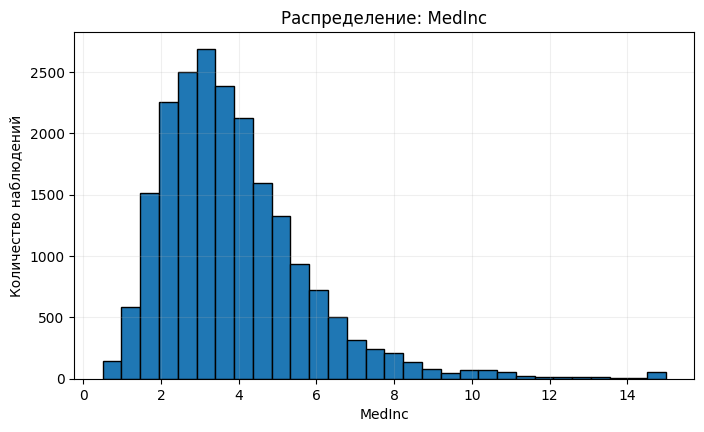

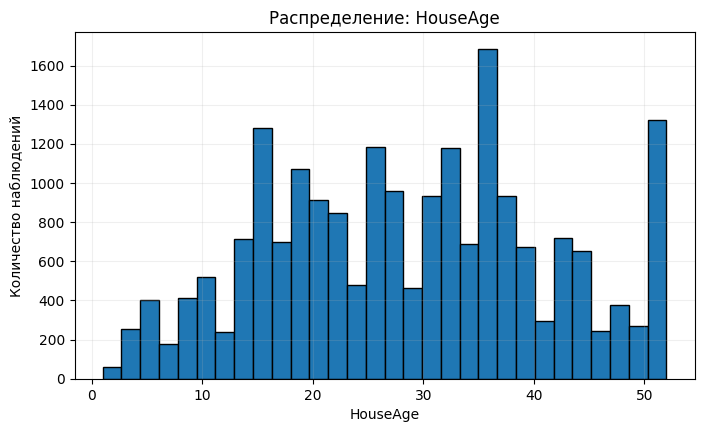

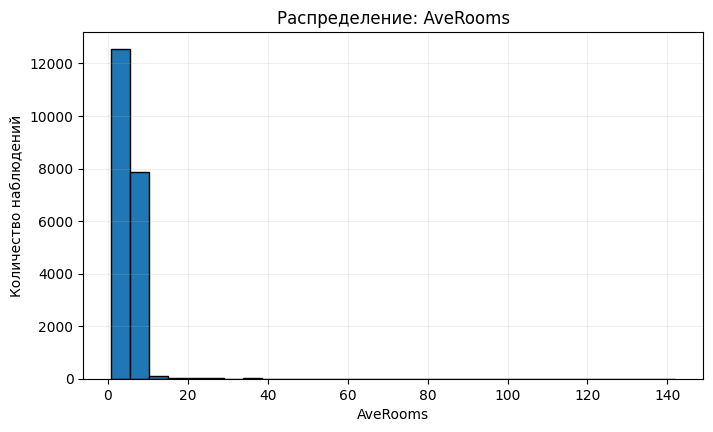

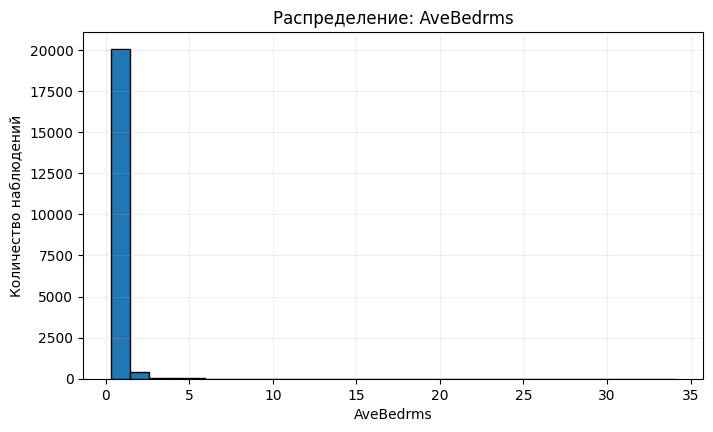

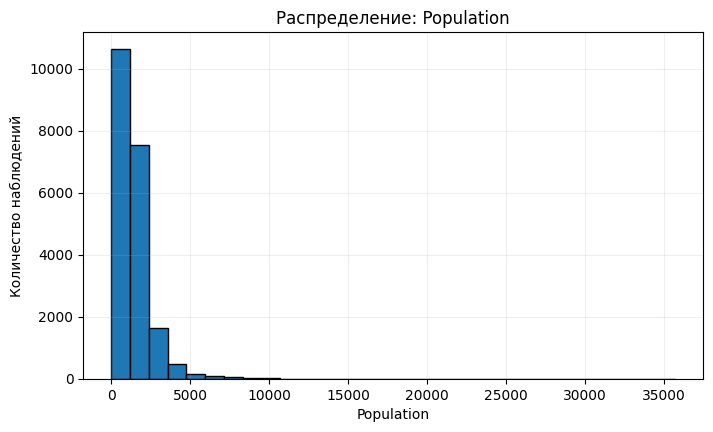

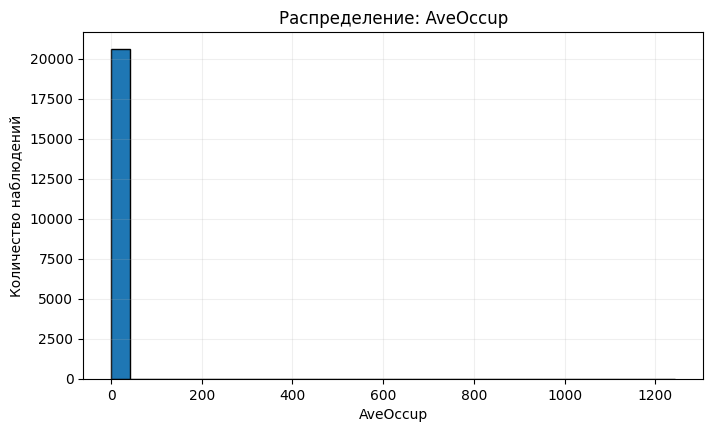

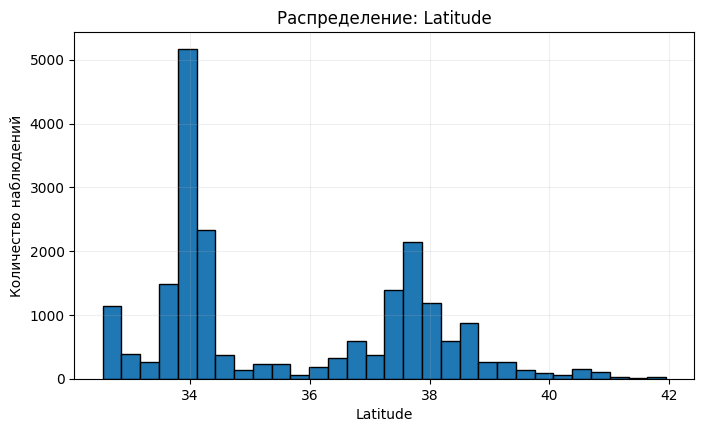

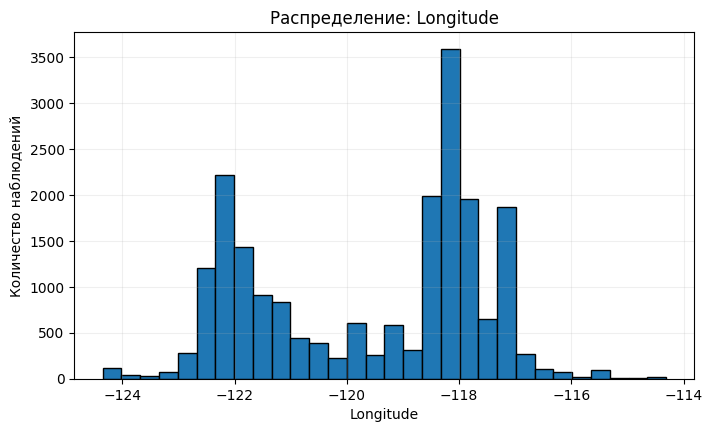

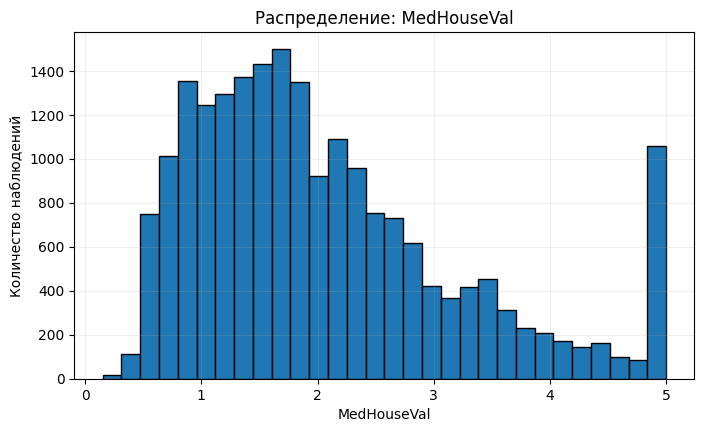

In [ ]:

# 5. Гистограммы распределения всех признаков и целевой переменной
for column in df.columns:
    plt.figure(figsize=(8, 4.5))
    plt.hist(df[column].dropna(), bins=30, edgecolor="black")
    plt.title(f"Распределение: {column}")
    plt.xlabel(column)
    plt.ylabel("Количество наблюдений")
    plt.grid(alpha=0.2)
    plt.show()


## 6. Выявление выбросов

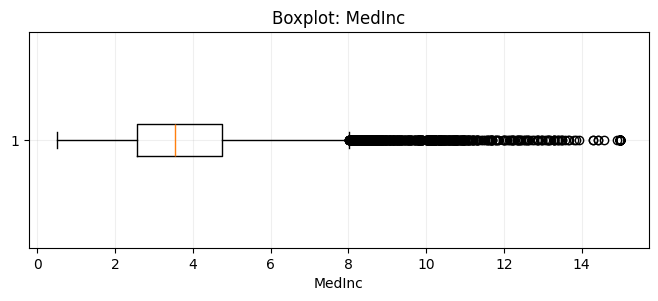

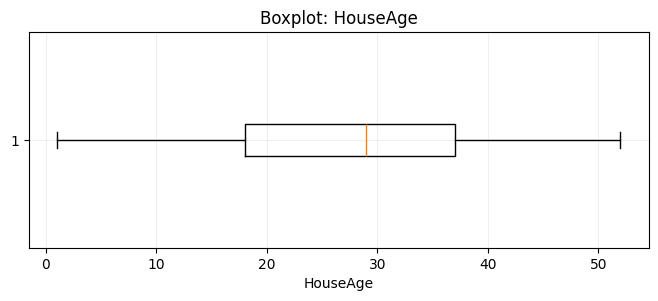

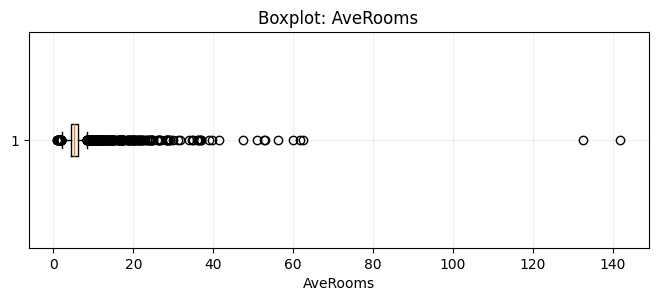

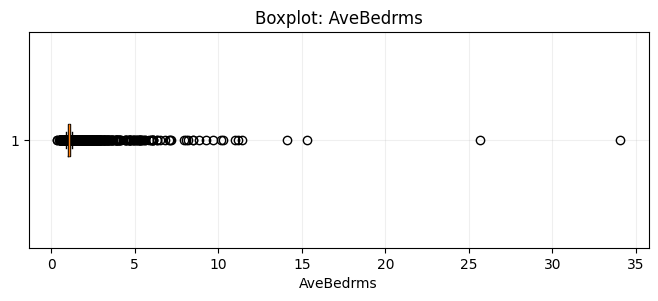

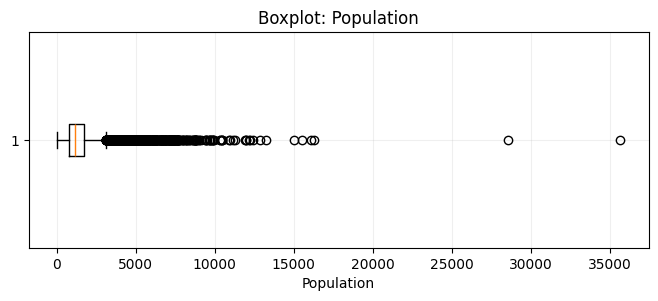

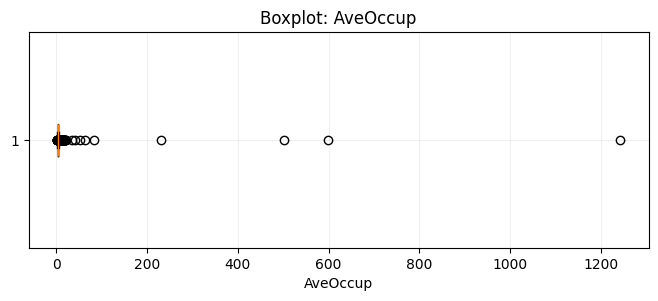

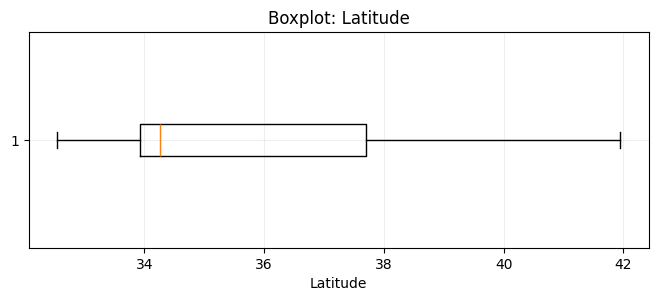

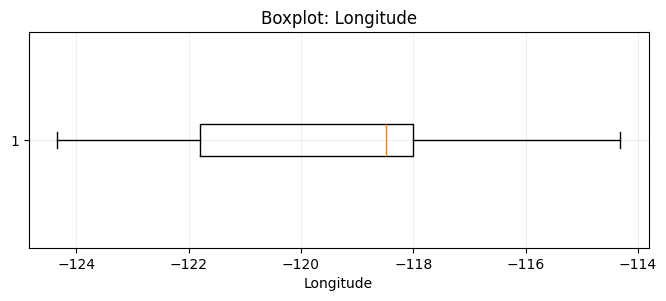

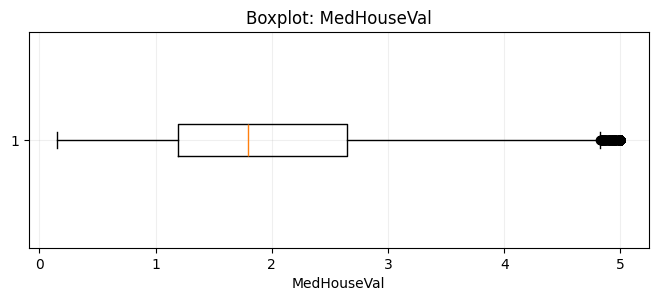

In [ ]:

# 6.1 Boxplot для каждого признака
for column in df.columns:
    plt.figure(figsize=(8, 2.8))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title(f"Boxplot: {column}")
    plt.xlabel(column)
    plt.grid(alpha=0.2)
    plt.show()


In [ ]:

# 6.2 Количественная оценка выбросов методом IQR
outlier_rows = []

for column in df.columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[column] < lower) | (df[column] > upper)).sum()
    percent = count / len(df) * 100

    outlier_rows.append({
        "Признак": column,
        "Q1": q1,
        "Q3": q3,
        "Нижняя граница IQR": lower,
        "Верхняя граница IQR": upper,
        "Количество выбросов": int(count),
        "Доля выбросов, %": round(percent, 2)
    })

outliers_table = pd.DataFrame(outlier_rows)
outliers_table


,Признак,Q1,Q3,Нижняя граница IQR,Верхняя граница IQR,Количество выбросов,"Доля выбросов, %"
0,MedInc,2.5634,4.7432,-0.7064,8.0130,681,3.3000
1,HouseAge,18.0000,37.0000,-10.5000,65.5000,0,0.0000
2,AveRooms,4.4407,6.0524,2.0232,8.4699,511,2.4800
3,AveBedrms,1.0061,1.0995,0.8659,1.2397,1424,6.9000
4,Population,787.0000,1725.0000,-620.0000,3132.0000,1196,5.7900
5,AveOccup,2.4297,3.2823,1.1510,4.5610,711,3.4400
6,Latitude,33.9300,37.7100,28.2600,43.3800,0,0.0000
7,Longitude,-121.8000,-118.0100,-127.4850,-112.3250,0,0.0000
8,MedHouseVal,1.1960,2.6472,-0.9809,4.8241,1071,5.1900


## 7. Анализ взаимосвязей и корреляций

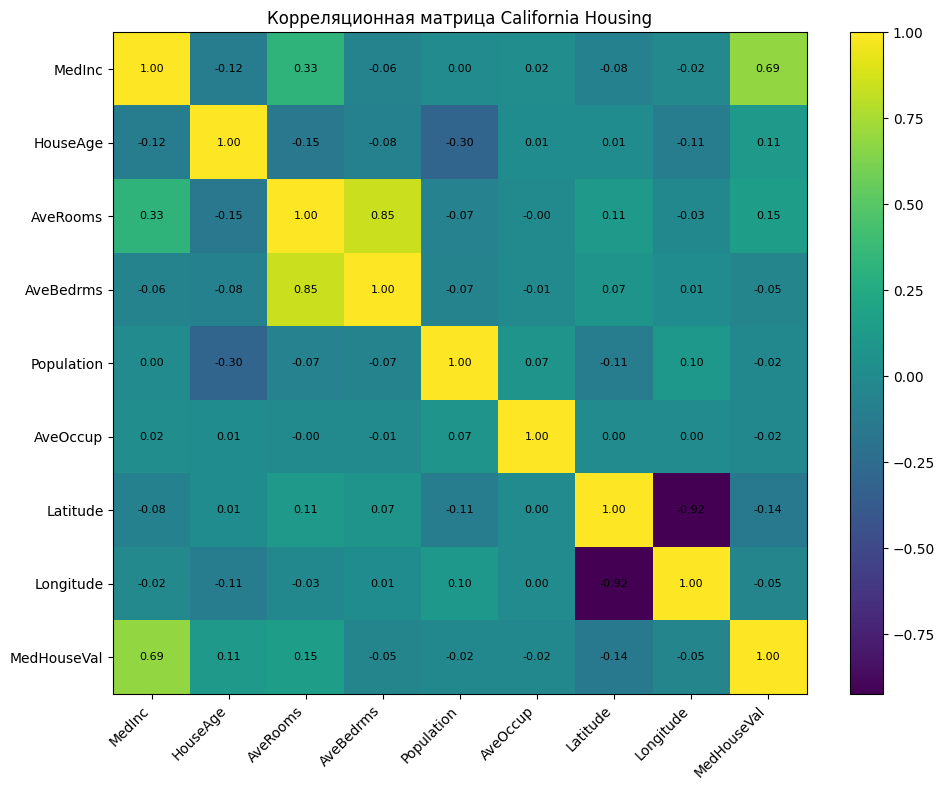

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.0000,-0.1190,0.3269,-0.0620,0.0048,0.0188,-0.0798,-0.0152,0.6881
HouseAge,-0.1190,1.0000,-0.1533,-0.0777,-0.2962,0.0132,0.0112,-0.1082,0.1056
AveRooms,0.3269,-0.1533,1.0000,0.8476,-0.0722,-0.0049,0.1064,-0.0275,0.1519
AveBedrms,-0.0620,-0.0777,0.8476,1.0000,-0.0662,-0.0062,0.0697,0.0133,-0.0467
Population,0.0048,-0.2962,-0.0722,-0.0662,1.0000,0.0699,-0.1088,0.0998,-0.0246
AveOccup,0.0188,0.0132,-0.0049,-0.0062,0.0699,1.0000,0.0024,0.0025,-0.0237
Latitude,-0.0798,0.0112,0.1064,0.0697,-0.1088,0.0024,1.0000,-0.9247,-0.1442
Longitude,-0.0152,-0.1082,-0.0275,0.0133,0.0998,0.0025,-0.9247,1.0000,-0.0460
MedHouseVal,0.6881,0.1056,0.1519,-0.0467,-0.0246,-0.0237,-0.1442,-0.0460,1.0000


In [ ]:

# 7.1 Корреляционная матрица
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
img = plt.imshow(corr, aspect="auto")
plt.colorbar(img)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Корреляционная матрица California Housing")
plt.tight_layout()
plt.show()

corr


In [ ]:

# 7.2 Корреляции признаков с целевой переменной
target_corr = (
    corr["MedHouseVal"]
    .drop("MedHouseVal")
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .to_frame("Корреляция с MedHouseVal")
)
target_corr


,Корреляция с MedHouseVal
MedInc,0.6881
AveRooms,0.1519
Latitude,-0.1442
HouseAge,0.1056
AveBedrms,-0.0467
Longitude,-0.0460
Population,-0.0246
AveOccup,-0.0237


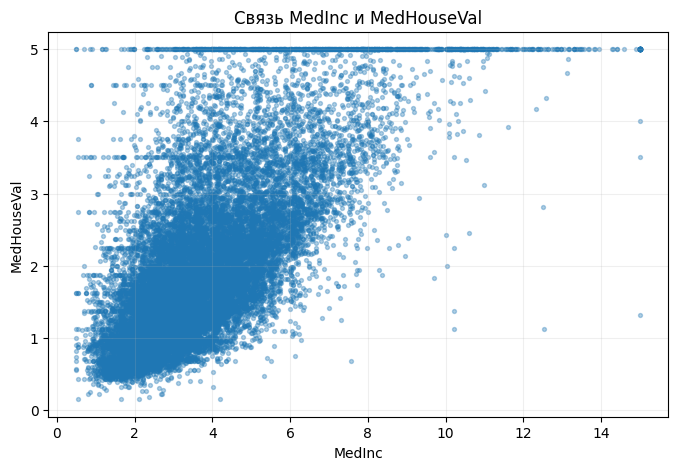

In [ ]:

# 7.3 Связь медианного дохода с целевой переменной
plt.figure(figsize=(8, 5))
plt.scatter(df["MedInc"], df["MedHouseVal"], s=8, alpha=0.35)
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")
plt.title("Связь MedInc и MedHouseVal")
plt.grid(alpha=0.2)
plt.show()


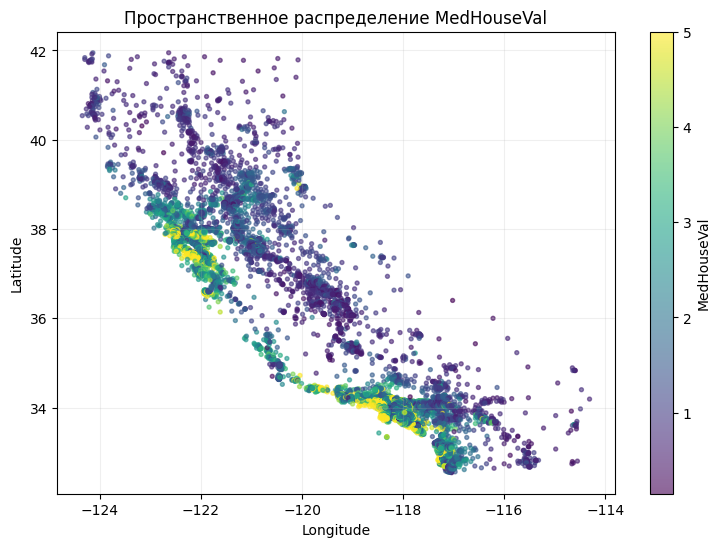

In [ ]:

# 7.4 Пространственное распределение стоимости жилья
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    s=8,
    alpha=0.6
)
plt.colorbar(scatter, label="MedHouseVal")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Пространственное распределение MedHouseVal")
plt.grid(alpha=0.2)
plt.show()



## 8. Категориальные признаки


In [ ]:

# 8. Проверка категориальных столбцов
categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Категориальные признаки:", categorical_columns)

if len(categorical_columns) == 0:
    print("Категориальных признаков нет — кодирование не требуется.")
else:
    print("Необходимо выполнить кодирование:", categorical_columns)


Категориальные признаки: []
Категориальных признаков нет — кодирование не требуется.



## 9. Разделение на признаки и целевую переменную


In [ ]:

# 9.1 X — входные признаки, y — целевая переменная
X = df.drop(columns=["MedHouseVal"]).copy()
y = df["MedHouseVal"].copy()

print("X:", X.shape)
print("y:", y.shape)
print("Признаки:", list(X.columns))


X: (20640, 8)
y: (20640,)
Признаки: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [ ]:

# 9.2 Разделение 80% / 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Доля train:", round(len(X_train) / len(X), 4))
print("Доля test :", round(len(X_test) / len(X), 4))


Размер обучающей выборки: (16512, 8)
Размер тестовой выборки: (4128, 8)
Доля train: 0.8
Доля test : 0.2


## 10. Обработка выбросов без утечки данных

In [ ]:

# 10. IQR-clipping для входных признаков
# Границы рассчитываются ТОЛЬКО по X_train и затем применяются к X_test.

X_train_clean = X_train.copy()
X_test_clean = X_test.copy()
outlier_bounds = {}

for column in X_train.columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # Координаты не обрезаем: крайние значения широты/долготы не являются ошибками.
    if column in ["Latitude", "Longitude"]:
        continue

    outlier_bounds[column] = (lower, upper)
    X_train_clean[column] = X_train_clean[column].clip(lower=lower, upper=upper)
    X_test_clean[column] = X_test_clean[column].clip(lower=lower, upper=upper)

print("IQR-clipping выполнен.")
print("Обработанные признаки:", list(outlier_bounds.keys()))


IQR-clipping выполнен.
Обработанные признаки: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup']


In [ ]:

# 10.2 Проверка после обработки
check_rows = []

for column, (lower, upper) in outlier_bounds.items():
    train_count = ((X_train_clean[column] < lower) | (X_train_clean[column] > upper)).sum()
    test_count = ((X_test_clean[column] < lower) | (X_test_clean[column] > upper)).sum()

    check_rows.append({
        "Признак": column,
        "За границами в train после обработки": int(train_count),
        "За границами в test после обработки": int(test_count)
    })

pd.DataFrame(check_rows)


,Признак,За границами в train после обработки,За границами в test после обработки
0,MedInc,0,0
1,HouseAge,0,0
2,AveRooms,0,0
3,AveBedrms,0,0
4,Population,0,0
5,AveOccup,0,0



## 11. Масштабирование числовых признаков


In [ ]:

# 11. Стандартизация
scaler = StandardScaler()

X_train_scaled_array = scaler.fit_transform(X_train_clean)
X_test_scaled_array = scaler.transform(X_test_clean)

X_train_scaled = pd.DataFrame(
    X_train_scaled_array,
    columns=X_train_clean.columns,
    index=X_train_clean.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled_array,
    columns=X_test_clean.columns,
    index=X_test_clean.index
)

print("Средние значения после масштабирования train (около 0):")
display(X_train_scaled.mean().round(4).to_frame("mean"))

print("Стандартные отклонения после масштабирования train (около 1):")
display(X_train_scaled.std(ddof=0).round(4).to_frame("std"))


Средние значения после масштабирования train (около 0):


,mean
MedInc,-0.0000
HouseAge,-0.0000
AveRooms,-0.0000
AveBedrms,-0.0000
Population,-0.0000
AveOccup,-0.0000
Latitude,0.0000
Longitude,0.0000


Стандартные отклонения после масштабирования train (около 1):


,std
MedInc,1.0000
HouseAge,1.0000
AveRooms,1.0000
AveBedrms,1.0000
Population,1.0000
AveOccup,1.0000
Latitude,1.0000
Longitude,1.0000


## 12. Финальная проверка готовности данных

In [ ]:

# 12.1 Проверка пропусков после всех преобразований
checks = {
    "X_train_clean пропуски": int(X_train_clean.isna().sum().sum()),
    "X_test_clean пропуски": int(X_test_clean.isna().sum().sum()),
    "X_train_scaled пропуски": int(X_train_scaled.isna().sum().sum()),
    "X_test_scaled пропуски": int(X_test_scaled.isna().sum().sum()),
    "y_train пропуски": int(y_train.isna().sum()),
    "y_test пропуски": int(y_test.isna().sum())
}

pd.Series(checks, name="Количество пропусков")


,Количество пропусков
X_train_clean пропуски,0
X_test_clean пропуски,0
X_train_scaled пропуски,0
X_test_scaled пропуски,0
y_train пропуски,0
y_test пропуски,0


In [ ]:

# 12.2 Итоговая информация
summary = pd.DataFrame({
    "Набор": [
        "X_train_clean",
        "X_test_clean",
        "X_train_scaled",
        "X_test_scaled",
        "y_train",
        "y_test"
    ],
    "Количество строк": [
        len(X_train_clean),
        len(X_test_clean),
        len(X_train_scaled),
        len(X_test_scaled),
        len(y_train),
        len(y_test)
    ],
    "Количество столбцов": [
        X_train_clean.shape[1],
        X_test_clean.shape[1],
        X_train_scaled.shape[1],
        X_test_scaled.shape[1],
        1,
        1
    ]
})
summary


,Набор,Количество строк,Количество столбцов
0,X_train_clean,16512,8
1,X_test_clean,4128,8
2,X_train_scaled,16512,8
3,X_test_scaled,4128,8
4,y_train,16512,1
5,y_test,4128,1


# КТ3 — Построение, обучение и сравнение **трёх** моделей

Сразу выбраны **Linear Regression, Ridge Regression (`alpha=1.0`) и Random Forest Regressor**.
- Для Linear Regression и Ridge Regression используем `X_train_scaled` / `X_test_scaled`.
- Для Random Forest используем `X_train_clean` / `X_test_clean`, без стандартизации.
- Все три алгоритма оцениваются на **одинаковой** тестовой выборке (`y_test`).

Результаты **предыдущего запуска** (будут пересчитаны после запуска ноутбука):

| Модель | MAE | MSE | RMSE | R² |
|:--|--:|--:|--:|--:|
| Linear Regression | 0.5031 | 0.4626 | 0.6801 | 0.6470 |
| Ridge Regression | 0.5031 | 0.4626 | 0.6801 | 0.6470 |
| Random Forest Regressor | **0.3294** | **0.2551** | **0.5050** | **0.8054** |

## 13.1 Подключение библиотек для трёх моделей

In [ ]:
# 13.1 КТ3: все три модели импортируем в одном месте
import time
import joblib
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Готово: LinearRegression, Ridge и RandomForestRegressor импортированы.")


## 13.2 Linear Regression — обычная линейная регрессия

In [ ]:
# 13.2 Linear Regression

linear_model = LinearRegression()

start_time = time.time()
linear_model.fit(X_train_scaled, y_train)
linear_train_time = time.time() - start_time

linear_predictions = linear_model.predict(X_test_scaled)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression обучена.")
print(f"Время обучения: {linear_train_time:.4f} сек.")
print(f"MAE  = {linear_mae:.4f}")
print(f"MSE  = {linear_mse:.4f}")
print(f"RMSE = {linear_rmse:.4f}")
print(f"R²   = {linear_r2:.4f}")


Linear Regression обучена.
Время обучения: 0.0549 сек.
MAE  = 0.5031
MSE  = 0.4626
RMSE = 0.6801
R²   = 0.6470


## 13.3 Ridge Regression — линейная модель с L2-регуляризацией

In [ ]:
# 13.3 Ridge Regression: часть основного сравнения, не отдельная добавка в конце
ridge_model = Ridge(alpha=1.0)

start_time = time.time()
ridge_model.fit(X_train_scaled, y_train)
ridge_train_time = time.time() - start_time

ridge_predictions = ridge_model.predict(X_test_scaled)
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_mse = mean_squared_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression обучена.")
print(f"Время обучения: {ridge_train_time:.4f} сек.")
print(f"MAE  = {ridge_mae:.4f}")
print(f"MSE  = {ridge_mse:.4f}")
print(f"RMSE = {ridge_rmse:.4f}")
print(f"R²   = {ridge_r2:.4f}")


## 13.4 Random Forest Regressor — ансамбль деревьев решений

In [ ]:
# 13.3 Random Forest Regressor

random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()
random_forest_model.fit(X_train_clean, y_train)
rf_train_time = time.time() - start_time

rf_predictions = random_forest_model.predict(X_test_clean)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regressor обучен.")
print(f"Время обучения: {rf_train_time:.4f} сек.")
print(f"MAE  = {rf_mae:.4f}")
print(f"MSE  = {rf_mse:.4f}")
print(f"RMSE = {rf_rmse:.4f}")
print(f"R²   = {rf_r2:.4f}")


Random Forest Regressor обучен.
Время обучения: 46.9637 сек.
MAE  = 0.3294
MSE  = 0.2551
RMSE = 0.5050
R²   = 0.8054


## 13.5 Сводное сравнение трёх моделей

Метрики рассчитываются **до** графиков, выбора лучшей модели и сохранения файла. Не округляем показатели при вычислениях — только при отображении.

In [ ]:
# 13.5 Сравниваем все три модели на одной тестовой выборке
results_df = pd.DataFrame([
    {"Модель": "Linear Regression", "MAE": linear_mae, "MSE": linear_mse,
     "RMSE": linear_rmse, "R²": linear_r2,
     "Время обучения, сек.": linear_train_time},
    {"Модель": "Ridge Regression", "MAE": ridge_mae, "MSE": ridge_mse,
     "RMSE": ridge_rmse, "R²": ridge_r2,
     "Время обучения, сек.": ridge_train_time},
    {"Модель": "Random Forest Regressor", "MAE": rf_mae, "MSE": rf_mse,
     "RMSE": rf_rmse, "R²": rf_r2,
     "Время обучения, сек.": rf_train_time},
])

print("Таблица сравнения трёх моделей:")
display(results_df.round(4))


## 13.6 Сравнительные графики RMSE и R² — сразу три модели

In [ ]:
# 13.6 Графики качества всех трёх моделей
for metric in ("RMSE", "R²"):
    plt.figure(figsize=(9, 5))
    plt.bar(results_df["Модель"], results_df[metric])
    plt.title(f"КТ3 — Сравнение трёх моделей по {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()


## 13.7 Фактические и прогнозируемые значения: Linear, Ridge и Random Forest

Диагональ `y=x` показывает идеальный прогноз. Здесь для каждой из трёх моделей строится свой график.

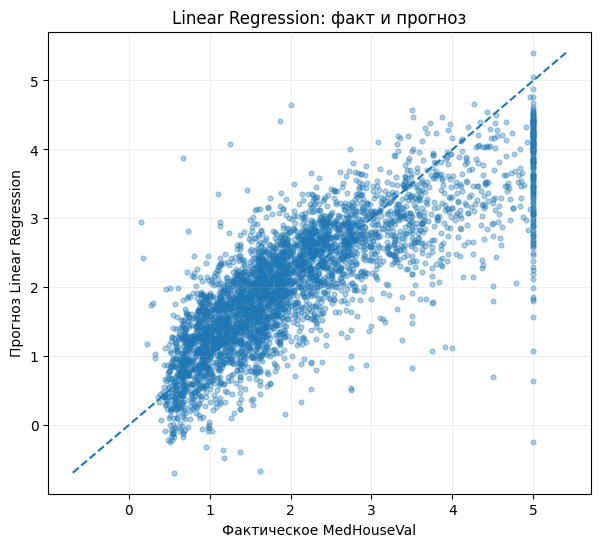

In [ ]:
# 13.7 График: Linear Regression
plt.figure(figsize=(7, 6))
plt.scatter(y_test, linear_predictions, s=12, alpha=0.35)
minimum = min(y_test.min(), linear_predictions.min())
maximum = max(y_test.max(), linear_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], "--")
plt.xlabel("Фактическое MedHouseVal")
plt.ylabel("Прогноз Linear Regression")
plt.title("Linear Regression: факт и прогноз")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


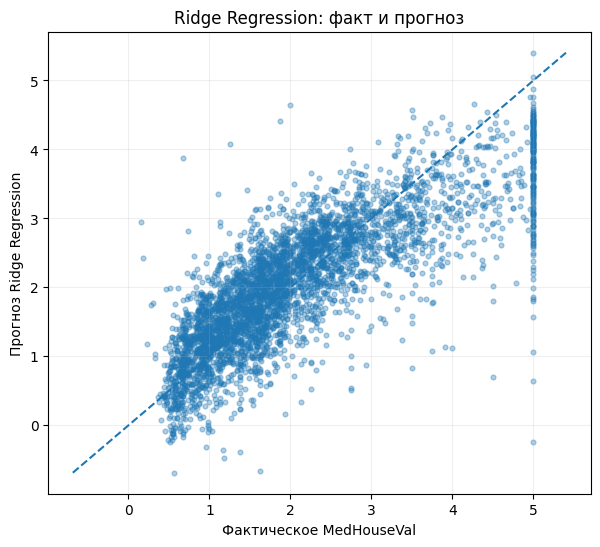

In [ ]:
# 13.7 График: Ridge Regression
plt.figure(figsize=(7, 6))
plt.scatter(y_test, ridge_predictions, s=12, alpha=0.35)
minimum = min(y_test.min(), ridge_predictions.min())
maximum = max(y_test.max(), ridge_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], "--")
plt.xlabel("Фактическое MedHouseVal")
plt.ylabel("Прогноз Ridge Regression")
plt.title("Ridge Regression: факт и прогноз")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


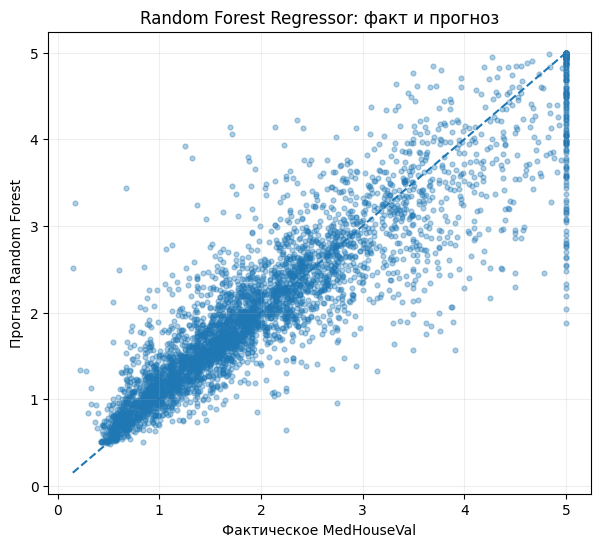

In [ ]:
# 13.7 График: Random Forest Regressor
plt.figure(figsize=(7, 6))
plt.scatter(y_test, rf_predictions, s=12, alpha=0.35)
minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], "--")
plt.xlabel("Фактическое MedHouseVal")
plt.ylabel("Прогноз Random Forest Regressor")
plt.title("Random Forest Regressor: факт и прогноз")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 13.8 Сравнение коэффициентов Linear Regression и Ridge Regression

In [ ]:
# 13.8 Как L2-регуляризация повлияла на коэффициенты
coefficients = pd.DataFrame({
    "Признак": list(X_train_scaled.columns),
    "Linear Regression": linear_model.coef_,
    "Ridge Regression": ridge_model.coef_
})
display(coefficients.round(4))


,Признак,Linear Regression,Ridge Regression
0,MedInc,0.8595,0.8596
1,HouseAge,0.1703,0.1704
2,AveRooms,-0.1456,-0.1456
3,AveBedrms,0.1605,0.1605
4,Population,0.0378,0.0378
5,AveOccup,-0.2648,-0.2648
6,Latitude,-0.8195,-0.8187
7,Longitude,-0.7500,-0.7493


## 13.9 Важность признаков Random Forest

In [ ]:
# 13.9 Важность признаков Random Forest

feature_importance = pd.DataFrame({
    "Признак": X_train_clean.columns,
    "Важность": random_forest_model.feature_importances_
}).sort_values("Важность", ascending=False)

feature_importance


,Признак,Важность
0,MedInc,0.5244
5,AveOccup,0.1379
6,Latitude,0.0898
7,Longitude,0.0895
1,HouseAge,0.0547
2,AveRooms,0.0448
4,Population,0.0315
3,AveBedrms,0.0274


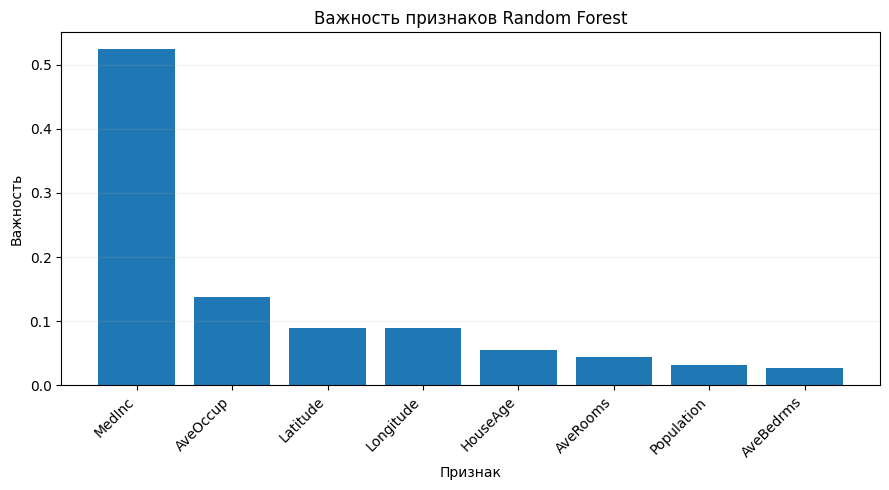

In [ ]:
# График важности признаков

plt.figure(figsize=(9, 5))
plt.bar(feature_importance["Признак"], feature_importance["Важность"])
plt.title("Важность признаков Random Forest")
plt.xlabel("Признак")
plt.ylabel("Важность")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


## 13.10 Выбор лучшей **из трёх** моделей

Выбираем модель по наибольшему R² (проверяем также MAE/RMSE); в предыдущем запуске это был Random Forest.

In [ ]:
# 13.10 Выбор лучшей модели с учётом Ridge Regression
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Random Forest Regressor": random_forest_model,
}

best_row = results_df.loc[results_df["R²"].idxmax()]
best_model_name = str(best_row["Модель"])
best_model = models[best_model_name]
best_uses_scaling = best_model_name in ("Linear Regression", "Ridge Regression")

print("Лучшая модель КТ3:", best_model_name)
print(f"R²: {best_row['R²']:.4f} | RMSE: {best_row['RMSE']:.4f} | MAE: {best_row['MAE']:.4f}")


## 13.11 Сохранение всех трёх моделей и предобработки для КТ4

In [ ]:
# 13.11 Формат ключей совместим с ранее созданным приложением Streamlit
bundle_kt3 = {
    "models": models,
    "scaler": scaler,
    "outlier_bounds": outlier_bounds,
    "feature_names": list(X_train.columns),
    "metrics": results_df,
    "best_model_name": best_model_name,
}

KT3_BUNDLE = "KT3_models_and_preprocessing.joblib"
joblib.dump(bundle_kt3, KT3_BUNDLE, compress=3)

print("Сохранено:", KT3_BUNDLE)
print("Модели:", ", ".join(bundle_kt3["models"]))
print("Лучшая:", bundle_kt3["best_model_name"])


# КТ4 — Вспомогательные файлы для приложения Streamlit

При выполнении этой ячейки создаются тестовые CSV-файлы. **Автоматическая загрузка не запускается**, чтобы Google Colab не выдавал несколько запросов скачивания при «Выполнить все». Для скачивания в следующей ячейке измените `DOWNLOAD_KT4_FILES` на `True`.

In [ ]:
# Подготавливаем правильный и намеренно ошибочный CSV
X_test.head(10).to_csv("sample_data.csv", index=False)
X_test.head(5).drop(columns=["MedInc"]).to_csv("invalid_data.csv", index=False)
print("Созданы файлы sample_data.csv и invalid_data.csv")

# Только если требуется скачать файлы на компьютер:
DOWNLOAD_KT4_FILES = False
if DOWNLOAD_KT4_FILES:
    from google.colab import files
    files.download(KT3_BUNDLE)
    files.download("sample_data.csv")
    files.download("invalid_data.csv")


# КТ5 — Настройка гиперпараметров Random Forest

**Цель:** проверить, может ли подбор параметров улучшить Random Forest Regressor (исходные R² ≈ 0.8054, RMSE ≈ 0.5050).

**Методика:**
1. Подбор проводится **только на `X_train`, `y_train`** с 3-кратной кросс-валидацией.
2. В каждой части кросс-валидации IQR-clipping **настраивается заново только на обучающей части fold**, а не заранее на всём train. Это исключает утечку между folds.
3. Полученные лучшие параметры переобучаются на полном train; тестовая выборка применяется только для итоговой проверки.
4. Исходные три модели и их результаты не перезаписываются. Сохраняется отдельный файл `KT5_models_and_preprocessing.joblib`.

Подбор может потребовать заметных вычислительных ресурсов. Реальные результаты будут доступны **после выполнения** ячеек КТ5.

## 14.1 Класс IQRClipper и пространство поиска

In [ ]:
# 14.1 Предобработка внутри каждого fold кросс-валидации
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline

class IQRClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        data = pd.DataFrame(X)
        self.columns_ = list(data.columns)
        self.bounds_ = {}
        for column in self.columns_:
            if column in ("Latitude", "Longitude"):
                continue
            q1, q3 = data[column].quantile([0.25, 0.75])
            iqr = q3 - q1
            self.bounds_[column] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
        return self

    def transform(self, X):
        data = pd.DataFrame(X, columns=self.columns_).copy()
        for column, (lower, upper) in self.bounds_.items():
            data[column] = data[column].clip(lower, upper)
        return data

cv_kt5 = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_pipeline = Pipeline([
    ("iqr", IQRClipper()),
    ("rf", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
])

parameter_space = {
    "rf__n_estimators": [100, 150, 200, 250],
    "rf__max_depth": [None, 15, 25, 35],
    "rf__min_samples_split": [2, 5, 10],
    "rf__min_samples_leaf": [1, 2, 4],
    "rf__max_features": [0.7, 1.0],
}

print("Параметры поиска КТ5 подготовлены.")


## 14.2 Кросс-валидация исходного Random Forest

In [ ]:
# 14.2 Базовая модель — 200 деревьев с тем же IQR внутри каждого fold
baseline_pipeline = Pipeline([
    ("iqr", IQRClipper()),
    ("rf", RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=1
    )),
])

baseline_cv_scores = cross_val_score(
    baseline_pipeline, X_train, y_train, cv=cv_kt5,
    scoring="neg_root_mean_squared_error", n_jobs=2
)
baseline_cv_rmse = -baseline_cv_scores.mean()
print(f"CV RMSE исходной Random Forest: {baseline_cv_rmse:.4f}")


## 14.3 RandomizedSearchCV — настройка модели

In [ ]:
# 14.3 Гиперпараметры ищем по обучающей выборке, тестовую не трогаем
search_kt5 = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=parameter_space,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=cv_kt5,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=1,
    refit=True,
)

start_time = time.time()
search_kt5.fit(X_train, y_train)
tuning_time = time.time() - start_time

optimized_cv_rmse = -search_kt5.best_score_
print("Поиск завершён.")
print("Лучшие гиперпараметры:", search_kt5.best_params_)
print(f"CV RMSE после подбора: {optimized_cv_rmse:.4f}")
print(f"Время всего поиска: {tuning_time:.1f} сек.")


## 14.4 Повторная оценка на той же тестовой выборке

In [ ]:
# 14.4 Поиск автоматически переобучил лучший pipeline на всём train
optimized_rf = search_kt5.best_estimator_.named_steps["rf"]
optimized_predictions = search_kt5.best_estimator_.predict(X_test)

# Дополнительная проверка идентичности предобработки КТ2 и КТ5
np.testing.assert_allclose(
    optimized_predictions, optimized_rf.predict(X_test_clean),
    rtol=1e-9, atol=1e-9
)

optimized_mae = mean_absolute_error(y_test, optimized_predictions)
optimized_mse = mean_squared_error(y_test, optimized_predictions)
optimized_rmse = np.sqrt(optimized_mse)
optimized_r2 = r2_score(y_test, optimized_predictions)

results_kt5 = pd.concat([
    results_df,
    pd.DataFrame([{
        "Модель": "Random Forest Optimized",
        "MAE": optimized_mae,
        "MSE": optimized_mse,
        "RMSE": optimized_rmse,
        "R²": optimized_r2,
        "Время обучения, сек.": search_kt5.refit_time_,
    }]),
], ignore_index=True)

print("КТ5: исходные модели и оптимизированный вариант")
display(results_kt5.round(4))
print(f"Изменение RMSE к исходной RF: {optimized_rmse - rf_rmse:+.4f}")
print(f"Изменение R² к исходной RF: {optimized_r2 - rf_r2:+.4f}")
print("CV RMSE исходной/оптимизированной:",
      f"{baseline_cv_rmse:.4f} / {optimized_cv_rmse:.4f}")


## 14.5 Графическое сравнение до и после оптимизации

In [ ]:
# 14.5 Для отчёта КТ5 — диаграммы всех четырёх вариантов
for metric in ("RMSE", "R²"):
    plt.figure(figsize=(10, 5))
    plt.bar(results_kt5["Модель"], results_kt5[metric])
    plt.title(f"КТ5 — До и после оптимизации: {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()


## 14.6 Выбор модели и сохранение артефактов КТ5

Для решения, какую версию Random Forest использовать по умолчанию, сравниваем **CV RMSE на обучающей выборке** (меньше — лучше). Значения тестовой выборки показываются для отчёта, но не используются для подбора гиперпараметров. Обе версии Random Forest сохраняются для сравнения.

In [ ]:
# 14.6 Сохраняем новую модель, не теряя три алгоритма из КТ3
models_kt5 = dict(models)
models_kt5["Random Forest Optimized"] = optimized_rf

use_optimized_by_cv = optimized_cv_rmse < baseline_cv_rmse
best_name_kt5 = (
    "Random Forest Optimized"
    if use_optimized_by_cv
    else "Random Forest Regressor"
)

bundle_kt5 = {
    "models": models_kt5,
    "scaler": scaler,
    "outlier_bounds": outlier_bounds,
    "feature_names": list(X_train.columns),
    "metrics": results_kt5,
    "best_model_name": best_name_kt5,
    "tuning_best_params": search_kt5.best_params_,
    "tuning_cv_rmse": optimized_cv_rmse,
    "baseline_cv_rmse": baseline_cv_rmse,
    "training_random_state": RANDOM_STATE,
}

KT5_BUNDLE = "KT5_models_and_preprocessing.joblib"
joblib.dump(bundle_kt5, KT5_BUNDLE, compress=3)

loaded_bundle = joblib.load(KT5_BUNDLE)
assert len(loaded_bundle["models"]) == 4
assert loaded_bundle["feature_names"] == list(X_train.columns)

print("КТ5: файл сохранён и успешно прочитан:", KT5_BUNDLE)
print("Модель по умолчанию (по CV):", best_name_kt5)
print("Доступные модели:", ", ".join(loaded_bundle["models"].keys()))


## 14.7 Получение файлов и перенос в Streamlit

Новый файл `KT5_models_and_preprocessing.joblib` сохраняет ключи, которые читает твой `app.py`: `models`, `scaler`, `outlier_bounds`, `feature_names`, `metrics`, `best_model_name`.

Чтобы приложение использовало **четыре** варианта (включая оптимизированную Random Forest), скачай `KT5_models_and_preprocessing.joblib`, положи его рядом с `app.py` и замени в `app.py` одну строку:

```python
MODEL_FILE = Path(__file__).parent / "KT5_models_and_preprocessing.joblib"
```

**Не удаляй старый `KT3_models_and_preprocessing.joblib` — он пригодится для сравнения.** После обновления повторно проверь ручное прогнозирование, CSV и графики. Для скачивания из Colab поменяй переключатель ниже на `True`.

In [ ]:
# Загрузка результатов на локальный компьютер (по запросу)
DOWNLOAD_KT5_FILE = False
if DOWNLOAD_KT5_FILE:
    from google.colab import files
    files.download(KT5_BUNDLE)
else:
    print("Артефакт КТ5 сохранён в Colab. Измени DOWNLOAD_KT5_FILE на True для скачивания.")
